## 1. Import libraries
These are the tools we need: pandas (tables), numpy (maths), matplotlib and seaborn (charts).

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the dataset
Click **Choose files** and upload the cars CSV from your computer.

In [42]:
df=pd.read_csv('/content/cardekho.csv')

## 3. Dataset overview
First we look at how big the data is, what columns it has, and what a few rows look like.

In [43]:
print("Rows and columns:", df.shape)
print()
print("Column names:", list(df.columns))

Rows and columns: (4340, 8)

Column names: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [44]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [45]:
df.info()      # shows the data type of each column and non-null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [46]:
# Separate number columns and text columns
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns  :", numeric_cols)
print("Categorical columns:", categorical_cols)

Numerical columns  : ['year', 'selling_price', 'km_driven']
Categorical columns: ['name', 'fuel', 'seller_type', 'transmission', 'owner']


**What each column means (edit if your dataset is different):**
- `name` - car brand and model
- `year` - year the car was made
- `selling_price` - price it is being sold for (INR)
- `km_driven` - kilometres the car has run
- `fuel` - Petrol / Diesel / CNG / LPG / Electric
- `seller_type` - Individual or Dealer
- `transmission` - Manual or Automatic
- `owner` - how many owners before

## 4. Data quality checks
We look for missing values, duplicate rows and messy category names.

In [47]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [48]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 763


In [49]:
# Check category labels for spelling problems
print(df["fuel"].unique())
print(df["seller_type"].unique())
print(df["transmission"].unique())
print(df["owner"].unique())

['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']
['Individual' 'Dealer' 'Trustmark Dealer']
['Manual' 'Automatic']
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


**Observation:** (write what you found - how many missing values? how many duplicates? any messy labels?)

## 5. Data cleaning
We save the size before cleaning so we can compare after.

In [50]:
rows_before = df.shape[0]
print("Rows before cleaning:", rows_before)

Rows before cleaning: 4340


**Step 1 - Remove duplicates.** A repeated row counts the same car twice and distorts averages.

In [51]:
df = df.drop_duplicates()

**Step 2 - Tidy the text.** Remove extra spaces and make capital letters consistent so `petrol` and `Petrol` are not treated as different.

In [52]:
df["fuel"] = df["fuel"].str.strip().str.title()
df["fuel"] = df["fuel"].replace({"Cng": "CNG", "Lpg": "LPG"})   # keep abbreviations in capitals
df["seller_type"] = df["seller_type"].str.strip().str.title()
df["transmission"] = df["transmission"].str.strip().str.title()
df["owner"] = df["owner"].str.strip()

**Step 3 - Missing values.** We drop a row only if price, year or km is empty. Guessing a car's price would be inventing data.

In [53]:
df = df.dropna(subset=["selling_price", "year", "km_driven"])

**Step 4 - Remove impossible values only** (zero price, negative km, a year in the future).

In [54]:
from datetime import date
current_year = date.today().year

df = df[(df["selling_price"] > 0) & (df["km_driven"] >= 0) & (df["year"] <= current_year)]

**Step 5 - Create new useful columns.** Brand comes from the first word of the name; age is current year minus year; price in lakh is easier to read.

In [55]:
df["brand"] = df["name"].str.split().str[0].str.title()
df["car_age"] = current_year - df["year"]
df["price_lakh"] = df["selling_price"] / 100000

**Step 6 - Outliers.** We check them but do NOT delete them, because very expensive cars are real luxury cars, not mistakes.

In [56]:
# IQR rule: values far above Q3 or below Q1 are outliers
q1 = df["price_lakh"].quantile(0.25)
q3 = df["price_lakh"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

price_outliers = df[df["price_lakh"] > upper_limit]
print("Price outliers:", len(price_outliers), "cars above", round(upper_limit, 2), "lakh")
price_outliers[["name", "year", "price_lakh"]].sort_values("price_lakh", ascending=False).head()

Price outliers: 170 cars above 12.0 lakh


,name,year,price_lakh
3872,Audi RS7 2015-2019 Sportback Performance,2016,89.0
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,81.5
3969,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,55.0
555,BMW X5 xDrive 30d xLine,2019,49.5
3453,BMW 5 Series 520d Luxury Line,2018,48.0


In [57]:
rows_after = df.shape[0]
print("Rows before cleaning:", rows_before)
print("Rows after cleaning :", rows_after)
print("Rows removed        :", rows_before - rows_after)
print("Columns now         :", df.shape[1])

Rows before cleaning: 4340
Rows after cleaning : 3577
Rows removed        : 763
Columns now         : 11


## 6. Descriptive statistics

In [58]:
df[["price_lakh", "km_driven", "year", "car_age"]].describe().round(2)

,price_lakh,km_driven,year,car_age
count,3577.00,3577.00,3577.00,3577.00
mean,4.74,69250.55,2012.96,13.04
std,5.09,47579.94,4.25,4.25
min,0.20,1.00,1992.00,6.00
25%,2.00,36000.00,2010.00,10.00
50%,3.50,60000.00,2013.00,13.00
75%,6.00,90000.00,2016.00,16.00
max,89.00,806599.00,2020.00,34.00


In [59]:
df[["brand", "fuel", "seller_type", "transmission", "owner"]].describe()

,brand,fuel,seller_type,transmission,owner
count,3577,3577,3577,3577,3577
unique,29,5,3,2,5
top,Maruti,Diesel,Individual,Manual,First Owner
freq,1072,1800,2832,3265,2218


In [60]:
print(df["fuel"].value_counts())
print()
print(df["transmission"].value_counts())
print()
print(df["owner"].value_counts())

fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64


**Observation:** (compare mean and median of price - are they far apart? what is the typical car age and km?)

## 7. Visual EDA
Nine charts: 3 univariate (one column), 4 bivariate (two columns), 2 multivariate (many columns).

### Chart 1 - How are prices distributed? (Histogram)

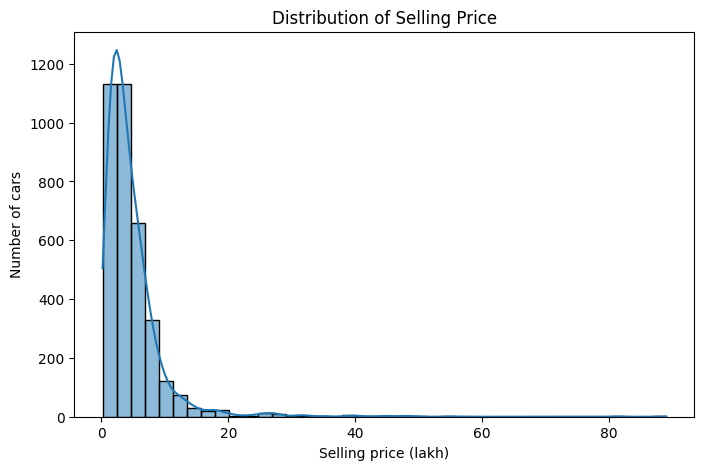

In [61]:
plt.figure(figsize=(8, 5))
sns.histplot(df["price_lakh"], bins=40, kde=True)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling price (lakh)")
plt.ylabel("Number of cars")
plt.show()

### Chart 2 - Which brands are most common? (Bar chart)

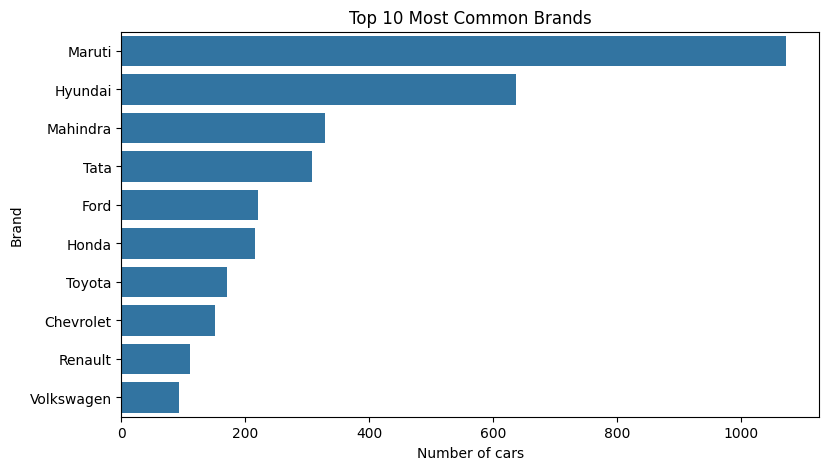

In [62]:
top_brands = df["brand"].value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title("Top 10 Most Common Brands")
plt.xlabel("Number of cars")
plt.ylabel("Brand")
plt.show()

**Observation:** Maruti wins the game!!

### Chart 3 - Which fuel types are common? (Count plot)

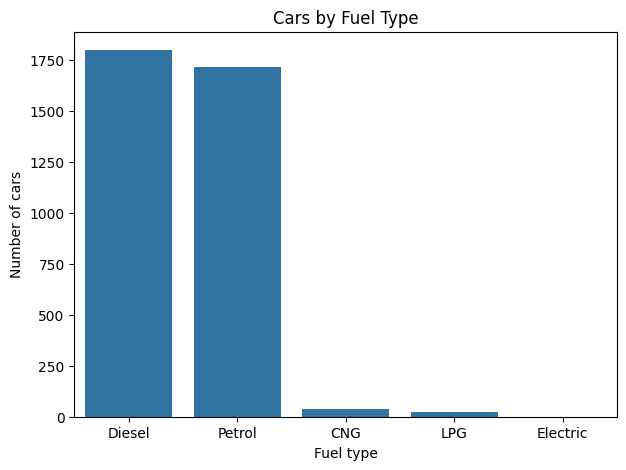

In [63]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="fuel", order=df["fuel"].value_counts().index)
plt.title("Cars by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Number of cars")
plt.show()

**Observation:** Diesel dominates.

### Chart 4 - Do automatic and manual cars differ in price? (Box plot)

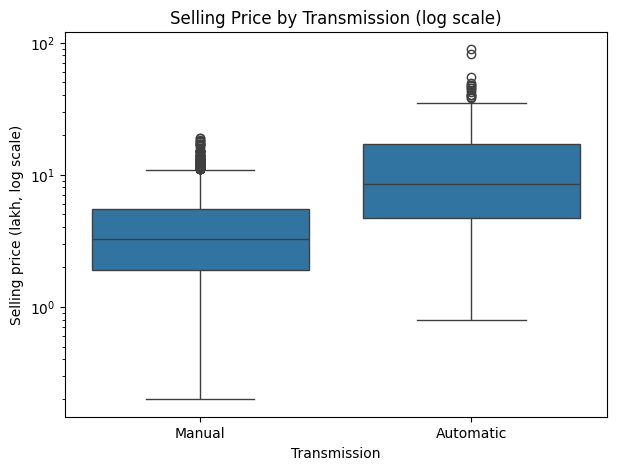

In [64]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="transmission", y="price_lakh")
plt.yscale("log")   # log scale stops a few very expensive cars from squashing the boxes
plt.title("Selling Price by Transmission (log scale)")
plt.xlabel("Transmission")
plt.ylabel("Selling price (lakh, log scale)")
plt.show()

**Observation:** East or  west Automatic is best.

### Chart 5 - How does age relate to price? (Scatter plot)

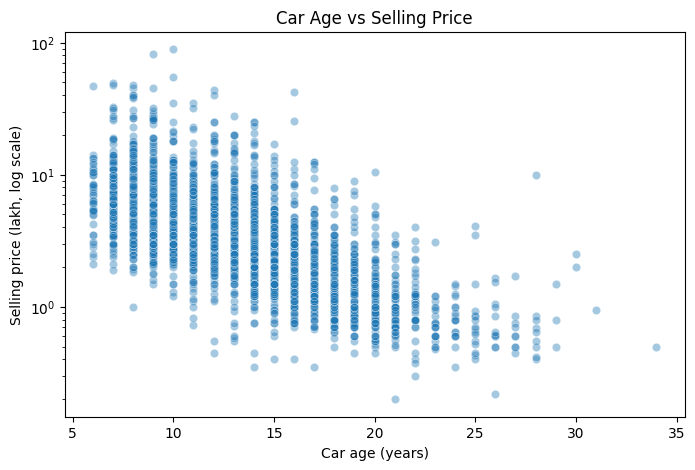

In [65]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="car_age", y="price_lakh", alpha=0.4)
plt.yscale("log")
plt.title("Car Age vs Selling Price")
plt.xlabel("Car age (years)")
plt.ylabel("Selling price (lakh, log scale)")
plt.show()

**Observation:** as age goes up, price decreases.

### Chart 6 - Does mileage influence price? (Scatter plot)

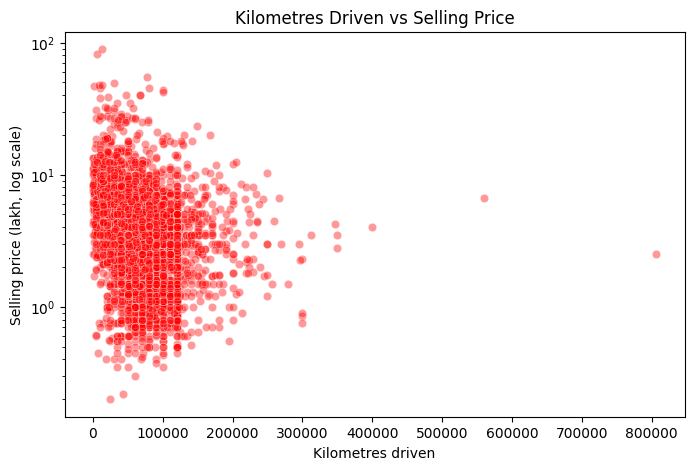

In [66]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="km_driven", y="price_lakh", alpha=0.4, color="red")
plt.yscale("log")
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres driven")
plt.ylabel("Selling price (lakh, log scale)")
plt.show()

### Chart 7 - Which brands cost the most on average? (Bar chart)

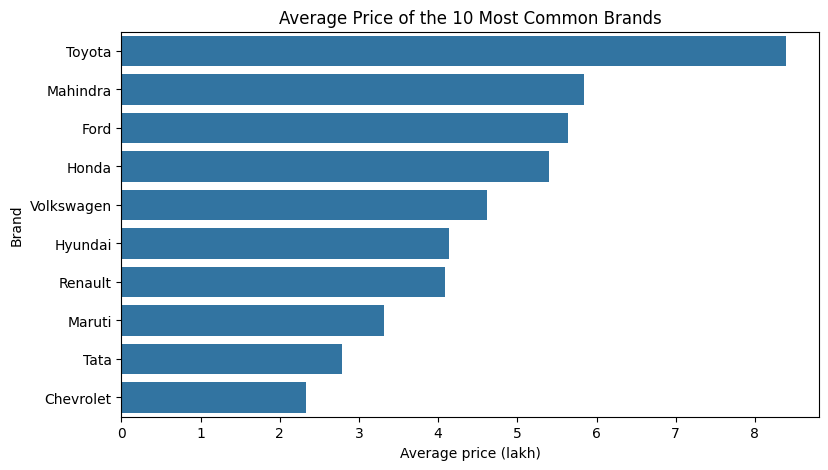

In [67]:
common_brands = df["brand"].value_counts().head(10).index
avg_price = df[df["brand"].isin(common_brands)].groupby("brand")["price_lakh"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=avg_price.values, y=avg_price.index)
plt.title("Average Price of the 10 Most Common Brands")
plt.xlabel("Average price (lakh)")
plt.ylabel("Brand")
plt.show()

**Observation:**  most expensive:-Toyota and least expensive:-Chevrolet

### Chart 8 - Which features are correlated? (Heatmap)

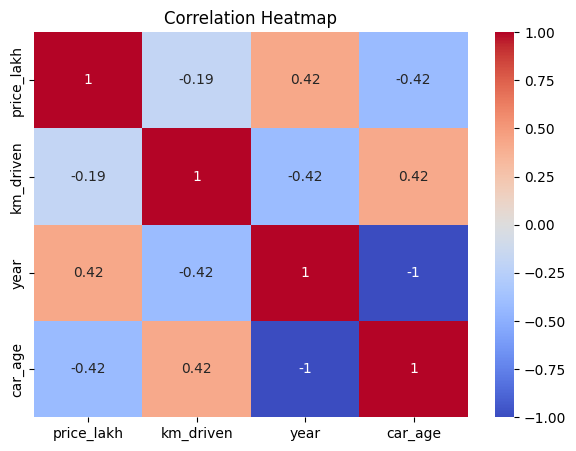

In [68]:
plt.figure(figsize=(7, 5))
corr = df[["price_lakh", "km_driven", "year", "car_age"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

### Chart 9 - Price by fuel type and transmission together (Box plot)

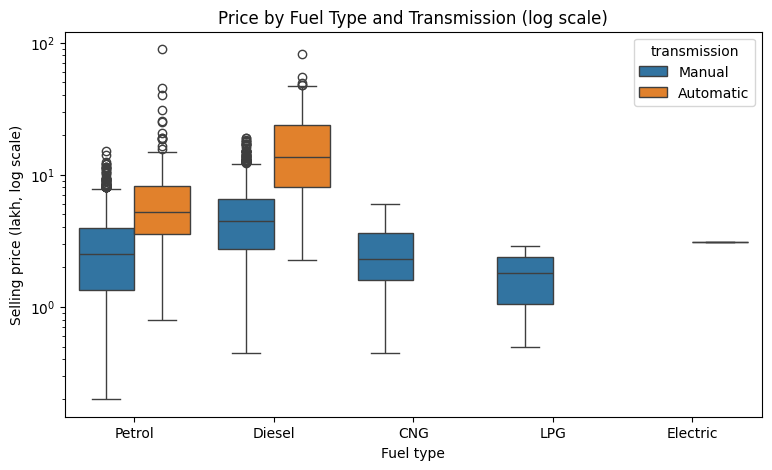

In [69]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="fuel", y="price_lakh", hue="transmission")
plt.yscale("log")
plt.title("Price by Fuel Type and Transmission (log scale)")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (lakh, log scale)")
plt.show()

**Observation:** Petrol+Automatic combination is most expensive?)

## 8. Key findings
Run this cell to get the numbers, then write each finding in your own words below it.

In [70]:
print("Most common brand :", df["brand"].value_counts().idxmax())
print("Most common fuel  :", df["fuel"].value_counts().idxmax())
print()
print("Mean price   (lakh):", round(df["price_lakh"].mean(), 2))
print("Median price (lakh):", round(df["price_lakh"].median(), 2))
print()
print("Correlation price vs car age :", round(df["price_lakh"].corr(df["car_age"]), 2))
print("Correlation price vs km      :", round(df["price_lakh"].corr(df["km_driven"]), 2))
print()
print("Median price by transmission:")
print(df.groupby("transmission")["price_lakh"].median().round(2))
print()
print("Most expensive brand (top 10 common):", avg_price.index[0], round(avg_price.iloc[0], 2), "lakh")
print("Number of price outliers:", len(price_outliers))

Most common brand : Maruti
Most common fuel  : Diesel

Mean price   (lakh): 4.74
Median price (lakh): 3.5

Correlation price vs car age : -0.42
Correlation price vs km      : -0.19

Median price by transmission:
transmission
Automatic    8.55
Manual       3.25
Name: price_lakh, dtype: float64

Most expensive brand (top 10 common): Toyota 8.39 lakh
Number of price outliers: 170


**Finding 1:** (brand / fuel popularity)

**Finding 2:** (price distribution: mean vs median)

**Finding 3:** (age vs price)

**Finding 4:** (mileage vs price)

**Finding 5:** (automatic vs manual)

**Finding 6 (optional):** (brand price differences / outliers)

### Limitations
- Correlation does not mean cause; we only describe patterns.
- The dataset has no engine size or horsepower, so we did not analyse them.
- Prices are listing prices from one source, so they may not represent the full market.

## 9. Conclusion
In this project, I performed Exploratory Data Analysis on a used-car dataset from CarDekho, which had 4340 rows and 11 columns before cleaning. I checked for missing values and duplicate rows, tidied the category labels, and removed 763 duplicate/invalid rows, leaving 3577 rows for analysis. I created new columns for brand, car age and price in lakh to make the data easier to understand.

Through the charts and statistics, I found that Maruti is the most common brand and Diesel is the most common fuel type. Car prices are left skewed, with a mean of 4.7391254207436395 lakh and a median of 3.5 lakh. Car age has a strong negative relationship with price (correlation = 0.42), while kilometres driven has a strong positive relationship (correlation = 0.42). Automatic and manual cars differ in median price: [Automatic 8.55 lakh vs Manual 3.25 lakh].

Challenges faced: The biggest challenge was that a few very expensive cars stretched the price charts, so I used a log scale to make the patterns readable. I also had to decide whether to remove outliers, and I kept them because they looked like genuine premium cars rather than errors. Cleaning inconsistent labels and creating the brand column from the car name also needed careful steps.

Limitations: The dataset has no engine size, horsepower or condition details, so I could not analyse those. The prices come from one source, and correlation does not prove that one factor causes another.

Future work: This analysis can be extended by building a machine-learning model to predict car prices, adding features such as engine size and mileage per litre, and comparing prices across different cities or years.